In [1]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display # 导入 display

# 设置 pandas 显示选项
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

print("库已导入，环境设置完毕。")

库已导入，环境设置完毕。


In [2]:
import pandas as pd
from pathlib import Path

# 设置文件路径
cleaned_file = Path("../output") / "levels_2005-2010.csv"

# 检查文件是否存在
if not cleaned_file.exists():
    print(f"错误：清洗后的文件不存在于 {cleaned_file}")
    print("请先运行 `python -m src.nucdiff.clean ...` 命令生成该文件。")
else:
    # 读取清洗后的数据
    df = pd.read_csv(cleaned_file)
    
    # 筛选 Z=93 的核素
    df_np = df[(df['Z'] == 95) & (df['year'] == 2005)].copy()
    # 正确的语法

    print(f"在 {cleaned_file.name} 中找到 {len(df_np)} 条 Z=93 (Np) 的能级记录。")
    print("="*50)
    
    # 为了更好地展示，我们将 nuclide 列也显示出来
    if not df_np.empty:
        display(df_np[['nuclide', 'Z', 'A', 'energy_keV', 'spin_parity', 'half_life', 'flag', 'year']])
    else:
        print("未找到 Z=93 的相关记录。")


在 levels_2005-2010.csv 中找到 492 条 Z=93 (Np) 的能级记录。


,nuclide,Z,A,energy_keV,spin_parity,half_life,flag,year
109587,AM-232,95,232,0.0,NaN,79 S,,2005
109883,AM-233,95,233,0.0,NaN,3.2 M,,2005
110042,AM-234,95,234,0.0,NaN,2.32 M,,2005
110351,AM-236,95,236,0.0,NaN,NaN,,2005
110672,AM-237,95,237,0.0,5/2(-),73.0 M,,2005
...,...,...,...,...,...,...,...,...
112149,AM-245,95,245,2400.0,NaN,640 NS,,2005
112233,AM-246,95,246,0.0,(7-),39 M,,2005
112234,AM-246,95,246,2000.0,NaN,73 US,,2005
112295,AM-247,95,247,0.0,(5/2),23.0 M,,2005


In [3]:
import pandas as pd
from pathlib import Path

# --- 配置 ---
# 这个目录应该和您运行 `clean.py` 时指定的 `--input_dir` 一致
# 如果您的原始 ENSDF 文件就在项目根目录，请使用 Path(".")
input_directory = Path("../")  

# 您可以修改年份来查看不同年份的原始文件
raw_data_year = 2005 

# 您可以修改元素符号来查看不同的核素 (例如 'U' 代表铀)
element_symbol = 'AM' # Z=93
# ---

# 构建文件路径
# clean.py 使用的是 'ENSDF-{year}' 这样的文件名格式
raw_file_path = input_directory / f"ENSDF-{raw_data_year}"

print(f"正在从原始文件 {raw_file_path.resolve()} 中查找所有与 '{element_symbol}' 相关的行...")
print("="*80)

if not raw_file_path.exists():
    print(f"错误：原始数据文件 {raw_file_path} 不存在。")
    print(f"请确认 `input_directory` 设置正确，并且该文件确实存在。")
else:
    found_lines = []
    # 简单地读取文件，找到所有包含核素符号的行
    # ENSDF格式中，核素ID通常在前8个字符内
    with raw_file_path.open('r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            # 检查前8个字符是否包含元素符号，这是一个快速查找的方法
            # 使用 .upper() 来忽略大小写
            if element_symbol.upper() in line[:8].upper():
                found_lines.append(line.strip('\n'))

    if found_lines:
        print(f"共找到 {len(found_lines)} 行。")
        # 显示所有找到的行，方便您完整检查
        for i, line in enumerate(found_lines):
            print(f"{i+1:03d}: {line}")
    else:
        print(f"在 {raw_file_path.name} 中未找到与 '{element_symbol}' 相关的记录。")


正在从原始文件 D:\VS CODE W\ENSDF-2005 中查找所有与 'AM' 相关的行...
共找到 6591 行。
001:  21NAM L MOMM1=+2.38630 10$MOME2=+0.05 4                                        
002:  31NAM L MOMM1=+2.305 8                                                         
003:  41CAMcL 7974, 7995, 8047.5, 8063.4, 8101.8, 8120, 8136.1, 8150.8, 8179.0,      
004: 245AM  P 0.0         (5/2)+            2.05 H    1                              
005: 124BAMTG           629.6                0.6           4        629.7 1   3.2 6  
006: 124BAMTG  2975.2   691.2                                                        
007: 124BAMTG  5009.6   405.6                                                        
008: 124BAMtG   n: Transition energy was given, but no intensity was give by authors.
009: 126BAMTG  2030     1774-256          0 - 2 - 0           0.31 3      1.06 5     
010: 181TAM L MOMM1=+2.3705 7$ MOME2=+3.28 6                                         
011: 181TAM L MOMM1=+5.28 9$ MOME2=+3.71 7                                  

In [4]:
# 查看原始清洗后的数据（归一化前）
# 路径已更正：从 notebook/ 目录上溯一级到项目根目录
raw_cleaned_path = Path("../output") / "levels_2005-2010.csv"
print(f"--- 显示来自 {raw_cleaned_path.resolve()} 的前20行数据 ---")
raw_df = pd.read_csv(raw_cleaned_path)
print(f"数据形状: {raw_df.shape}")
print(f"列名: {list(raw_df.columns)}")
display(raw_df.head(50))


--- 显示来自 D:\VS CODE W\output\levels_2005-2010.csv 的前20行数据 ---
数据形状: (728581, 12)
列名: ['nuclide', 'Z', 'A', 'energy_keV', 'spin_parity', 'half_life', 'source_dataset_id', 'dataset_type', 'flag', 'is_stable', 'level_id', 'year']


,nuclide,Z,A,energy_keV,spin_parity,half_life,source_dataset_id,dataset_type,flag,is_stable,level_id,year
0,H-1,1,1,0.00,1/2+,STABLE,1H,ADOPTED,,True,0,2005
1,H-2,1,2,0.00,1+,STABLE,2H,ADOPTED,,True,2,2005
2,H-3,1,3,0.00,1/2+,12.32 Y,3H,ADOPTED,,False,4,2005
3,HE-3,2,3,0.00,1/2+,STABLE,3HE,ADOPTED,,True,6,2005
4,H-4,1,4,0.00,2-,NaN,4H,ADOPTED,,False,8,2005
5,H-4,1,4,310.00,1-,6.73 MEV,4H,ADOPTED,,False,9,2005
6,H-4,1,4,2080.00,0-,8.92 MEV,4H,ADOPTED,,False,10,2005
7,H-4,1,4,2830.00,1-,12.99 MEV,4H,ADOPTED,,False,11,2005
8,HE-4,2,4,0.00,0+,STABLE,4HE,ADOPTED,,True,12,2005
9,HE-4,2,4,20.21,0+,0.50 MEV,4HE,ADOPTED,,False,13,2005


In [5]:
# 加载预处理后的训练数据（归一化后）
# 路径已更正：从 notebook/ 目录上溯一级到项目根目录
preprocessed_path = Path("../clean_data_split") / 'task_L_years_2005-2010_seed_412_frac_0.20_train.feather'
print(f"--- 加载来自 {preprocessed_path.resolve()} 的预处理数据 ---")
df = pd.read_feather(preprocessed_path)
df.dropna(subset=['energy_keV'], inplace=True)
print(f"数据形状: {df.shape}")
print(f"列名: {list(df.columns)}")
print("预处理数据加载成功。")
display(df.head(10))


--- 加载来自 D:\VS CODE W\clean_data_split\task_L_years_2005-2010_seed_412_frac_0.20_train.feather 的预处理数据 ---
数据形状: (606635, 29)
列名: ['A_int', 'A_int_scaled', 'N_int', 'N_int_scaled', 'Z_int', 'Z_int_scaled', 'asym', 'asym_scaled', 'delta_magic_n', 'delta_magic_n_scaled', 'delta_magic_z', 'delta_magic_z_scaled', 'energy_keV', 'energy_keV_scaled', 'has_tau', 'is_adopted', 'is_isomer', 'is_lifetime_censored', 'is_stable', 'is_unbound', 'log10_tau_s', 'log10_tau_s_scaled', 'n', 'pairing_type', 'parity', 'record_type_idx', 'source_dataset_id', 'twice_J', 'year']
预处理数据加载成功。


,A_int,A_int_scaled,N_int,N_int_scaled,Z_int,Z_int_scaled,asym,asym_scaled,delta_magic_n,delta_magic_n_scaled,delta_magic_z,delta_magic_z_scaled,energy_keV,energy_keV_scaled,has_tau,is_adopted,is_isomer,is_lifetime_censored,is_stable,is_unbound,log10_tau_s,log10_tau_s_scaled,n,pairing_type,parity,record_type_idx,source_dataset_id,twice_J,year
0,1,-2.139891,0,-2.023731,1,-2.306784,-0.999999,-17.569342,2,-0.977213,1,-1.150930,0.00,-0.801008,0,0,0,1,1,0,9.499104,1.048358,0,1,2,0,1H,2,2005
1,2,-2.122474,1,-1.995454,1,-2.306784,0.000000,-2.069913,1,-1.135468,1,-1.150930,0.00,-0.801008,0,0,0,1,1,0,9.499104,1.048358,1,3,2,0,2H,3,2005
2,3,-2.105058,2,-1.967178,1,-2.306784,0.333333,3.096566,0,-1.293724,1,-1.150930,0.00,-0.801008,1,0,0,0,0,0,8.748592,1.024148,2,1,2,0,3H,2,2005
3,3,-2.105058,1,-1.995454,2,-2.261813,-0.333333,-7.236393,1,-1.135468,0,-1.368361,0.00,-0.801008,0,0,0,1,1,0,9.499104,1.048358,1,2,2,0,3HE,2,2005
4,4,-2.087641,3,-1.938902,1,-2.306784,0.500000,5.679807,1,-1.135468,1,-1.150930,0.00,-0.801008,0,0,0,0,0,0,-25.000000,-0.064516,3,3,0,0,4H,5,2005
5,4,-2.087641,3,-1.938902,1,-2.306784,0.500000,5.679807,1,-1.135468,1,-1.150930,310.00,-0.473928,1,0,0,0,0,1,-22.009649,0.031947,3,3,0,0,4H,3,2005
6,4,-2.087641,3,-1.938902,1,-2.306784,0.500000,5.679807,1,-1.135468,1,-1.150930,2080.00,1.393594,1,0,0,0,0,1,-22.131999,0.028000,3,3,0,0,4H,1,2005
7,4,-2.087641,3,-1.938902,1,-2.306784,0.500000,5.679807,1,-1.135468,1,-1.150930,2830.00,2.184917,1,0,0,0,0,1,-22.295243,0.022734,3,3,0,0,4H,3,2005
8,4,-2.087641,2,-1.967178,2,-2.261813,0.000000,-2.069913,0,-1.293724,0,-1.368361,0.00,-0.801008,0,0,0,1,1,0,9.499104,1.048358,2,0,2,0,4HE,1,2005
9,4,-2.087641,2,-1.967178,2,-2.261813,0.000000,-2.069913,0,-1.293724,0,-1.368361,20.21,-0.779685,1,0,0,0,0,1,-20.880604,0.068368,2,0,2,0,4HE,1,2005


In [6]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

def run_baselines(dataframe, feature_cols, label_col):
    """在给定的数据上训练和评估 Ridge 与 LightGBM 模型。"""
    X = dataframe[feature_cols].values
    y = dataframe[label_col].values

    X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=412)
    print(f"数据已分割: {len(X_tr)} 训练样本, {len(X_val)} 验证样本。")

    # --- 基线 1: Ridge 回归 ---
    print("\n--- 训练基线 1: Ridge Regression ---")
    scaler = StandardScaler().fit(X_tr)
    X_tr_std = scaler.transform(X_tr)
    X_val_std = scaler.transform(X_val)
    lin = Ridge(alpha=1.0).fit(X_tr_std, y_tr)
    pred_lin = lin.predict(X_val_std)
    print(f"线性模型 (Ridge) -> R2 = {r2_score(y_val, pred_lin):.4f}, MAE = {mean_absolute_error(y_val, pred_lin):.2f} keV")

    # --- 基线 2: LightGBM ---
    print("\n--- 训练基线 2: LightGBM ---")
    # 修正：将无效的变量名 '1gbm' 修改为 'lgbm'
    lgbm = lgb.LGBMRegressor(num_leaves=64, n_estimators=500, random_state=412, verbosity=-1)
    lgbm.fit(X_tr, y_tr,
             eval_set=[(X_val, y_val)],
             callbacks=[lgb.early_stopping(10, verbose=False)],
             feature_name=feature_cols)
    
    # 修正：使用一致的变量名 'pred_lgbm'
    pred_lgbm = lgbm.predict(X_val)
    # 修正：在打印时使用正确的变量名 'pred_lgbm'
    print(f"LightGBM -> R2 = {r2_score(y_val, pred_lgbm):.4f}, MAE = {mean_absolute_error(y_val, pred_lgbm):.2f} keV")

    return lgbm


In [7]:
# 实验 A: 在全部数据上运行基线 (包含基态)
print("--- 实验 A: 在全部数据上运行基线 (包含基态) ---")

# 修正：使用重构后的正确列名 ('Z_int', 'A_int', 'N_int')
feature_names = ['Z_int', 'A_int', 'N_int', 'pairing_type', 'delta_magic_z', 'delta_magic_n', 'asym']

lgbm_full = run_baselines(df, feature_names, 'energy_keV')

--- 实验 A: 在全部数据上运行基线 (包含基态) ---
数据已分割: 485308 训练样本, 121327 验证样本。

--- 训练基线 1: Ridge Regression ---
线性模型 (Ridge) -> R2 = 0.0693, MAE = 764.89 keV

--- 训练基线 2: LightGBM ---
LightGBM -> R2 = 0.2147, MAE = 645.47 keV


c:\Users\pianng\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [8]:
# 实验 B: 在过滤后的数据上运行基线 (不含基态)
print("\n--- 实验 B: 在过滤后的数据上运行基线 (不含基态) ---")
original_count = len(df)
# 过滤掉基态 (energy_keV 约等于 0)
df_filtered = df[df.energy_keV > 1e-3].copy()
print(f"已过滤基态数据。保留 {len(df_filtered)} / {original_count} 条记录 ({(len(df_filtered)/original_count):.2%})")

# 使用与实验A相同的、修正后的特征名列表
lgbm_filtered = run_baselines(df_filtered, feature_names, 'energy_keV')


--- 实验 B: 在过滤后的数据上运行基线 (不含基态) ---
已过滤基态数据。保留 593880 / 606635 条记录 (97.90%)
数据已分割: 475104 训练样本, 118776 验证样本。

--- 训练基线 1: Ridge Regression ---
线性模型 (Ridge) -> R2 = 0.0765, MAE = 767.74 keV

--- 训练基线 2: LightGBM ---


c:\Users\pianng\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM -> R2 = 0.2227, MAE = 646.99 keV


In [9]:
# --- 增强版特征 ---
# 这个列表包含了我们之前所有特征工程的成果
# 目的是检验一个更强大的模型性能
feature_names = [
    # 标准化后的核心特征
    'Z_int_scaled', 'A_int_scaled', 'N_int_scaled',
    'delta_magic_z_scaled', 'delta_magic_n_scaled', 'asym_scaled',
    
    # 寿命相关特征
    'log10_tau_s_scaled',
    
    # 解析后的Jπ特征
    'twice_J', 'parity',
    
    # 类别/布尔特征
    'pairing_type', 'record_type_idx',
    'has_tau', 'is_lifetime_censored', 'is_unbound', 'is_stable', 'is_isomer', 'is_adopted'
]

# --- 实验 A: 在全部数据上运行基线 (包含基态) ---
print("--- 实验 A: 在全部数据上运行基线 (包含基态) ---")
lgbm_full = run_baselines(df, feature_names, 'energy_keV')


# --- 实验 B: 在过滤后的数据上运行基线 (不含基态) ---
print("\n--- 实验 B: 在过滤后的数据上运行基线 (不含基态) ---")
original_count = len(df)
df_filtered = df[df.energy_keV > 1e-3].copy()
print(f"已过滤基态数据。保留 {len(df_filtered)} / {original_count} 条记录 ({(len(df_filtered)/original_count):.2%})")

# 使用同样的增强特征列表
lgbm_filtered = run_baselines(df_filtered, feature_names, 'energy_keV')


--- 实验 A: 在全部数据上运行基线 (包含基态) ---
数据已分割: 485308 训练样本, 121327 验证样本。

--- 训练基线 1: Ridge Regression ---
线性模型 (Ridge) -> R2 = 0.0935, MAE = 751.37 keV

--- 训练基线 2: LightGBM ---


c:\Users\pianng\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM -> R2 = 0.4302, MAE = 501.57 keV

--- 实验 B: 在过滤后的数据上运行基线 (不含基态) ---
已过滤基态数据。保留 593880 / 606635 条记录 (97.90%)
数据已分割: 475104 训练样本, 118776 验证样本。

--- 训练基线 1: Ridge Regression ---
线性模型 (Ridge) -> R2 = 0.0908, MAE = 759.57 keV

--- 训练基线 2: LightGBM ---
LightGBM -> R2 = 0.4348, MAE = 504.21 keV


c:\Users\pianng\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



--- 来自 LightGBM 的特征重要性 (已过滤基态数据) ---


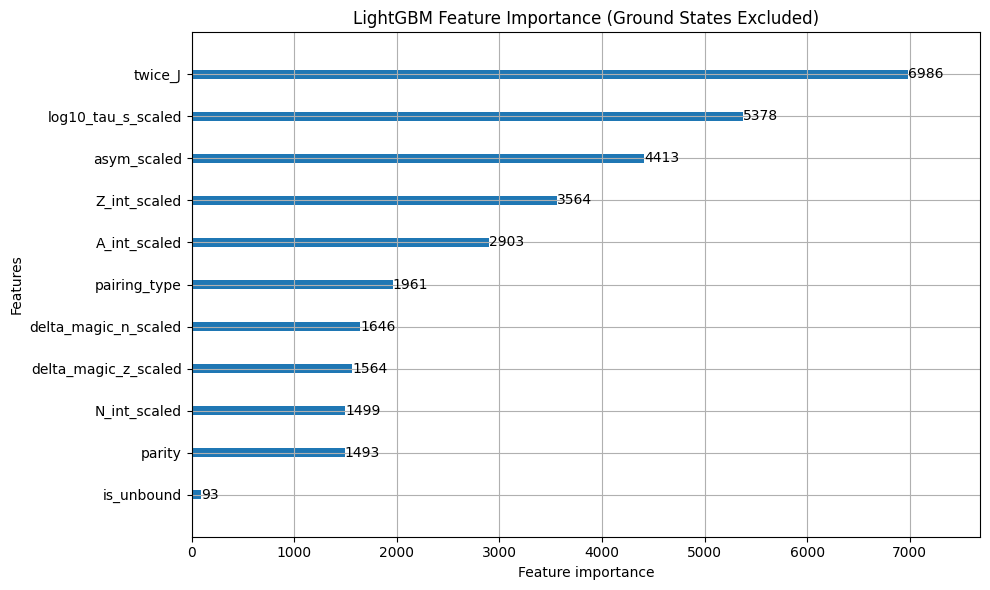

In [10]:
# 绘制特征重要性
print("\n--- 来自 LightGBM 的特征重要性 (已过滤基态数据) ---")
fig, ax = plt.subplots(figsize=(10, 6))
lgb.plot_importance(lgbm_filtered, ax=ax, max_num_features=20)
plt.title("LightGBM Feature Importance (Ground States Excluded)")
plt.tight_layout()
plt.show()


--- 能量分布统计 ---
总样本数: 606635
基态样本数 (energy_keV ≈ 0): 12755
激发态样本数 (energy_keV > 0): 593880
基态占比: 2.10%


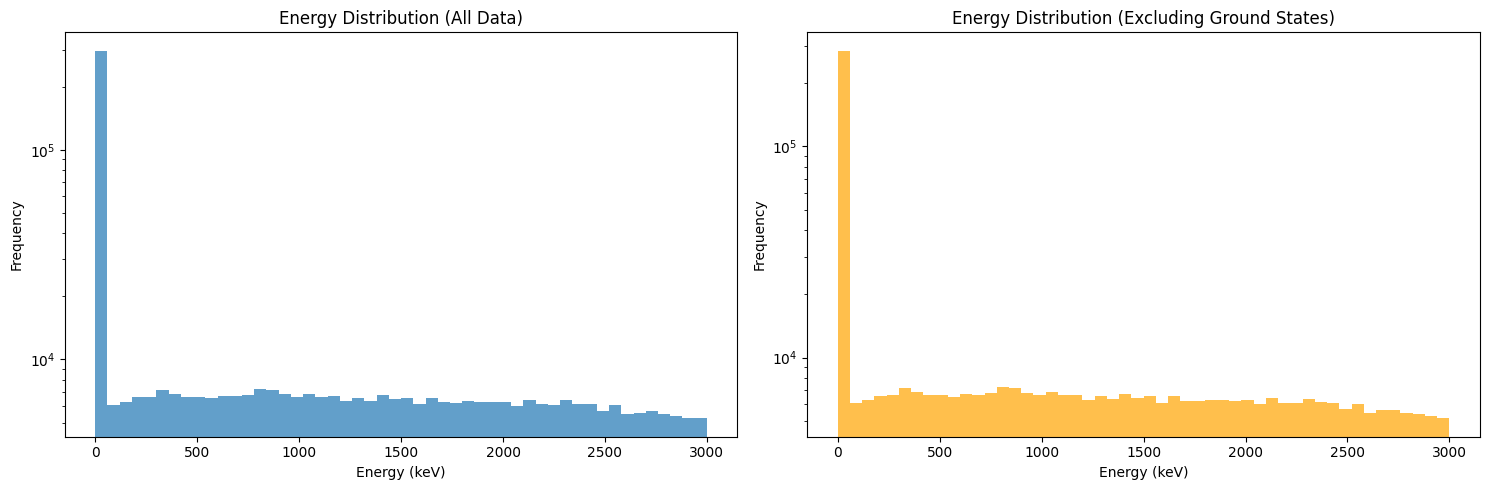

In [11]:
# 分析能量分布
print("--- 能量分布统计 ---")
print(f"总样本数: {len(df)}")
print(f"基态样本数 (energy_keV ≈ 0): {len(df[df.energy_keV < 1e-3])}")
print(f"激发态样本数 (energy_keV > 0): {len(df[df.energy_keV > 1e-3])}")
print(f"基态占比: {len(df[df.energy_keV < 1e-3])/len(df):.2%}")

# 绘制能量分布直方图
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 全部数据的能量分布
ax1.hist(df.energy_keV, bins=50, alpha=0.7)
ax1.set_xlabel('Energy (keV)')
ax1.set_ylabel('Frequency')
ax1.set_title('Energy Distribution (All Data)')
ax1.set_yscale('log')

# 过滤基态后的能量分布
ax2.hist(df_filtered.energy_keV, bins=50, alpha=0.7, color='orange')
ax2.set_xlabel('Energy (keV)')
ax2.set_ylabel('Frequency')
ax2.set_title('Energy Distribution (Excluding Ground States)')
ax2.set_yscale('log')

plt.tight_layout()
plt.show()


In [12]:
# --- 终极特征集：包含所有创建的数值和类别特征 ---
feature_names = [
    # 标准化后的核心特征
    'Z_int_scaled', 'A_int_scaled', 'N_int_scaled',
    'delta_magic_z_scaled', 'delta_magic_n_scaled', 'asym_scaled',
    
    # 寿命相关特征
    'log10_tau_s_scaled',
    
    # 解析后的Jπ特征
    'twice_J', 'parity',
    
    # 类别/布尔特征
    'pairing_type', 'record_type_idx',
    'has_tau', 'is_lifetime_censored', 'is_unbound', 'is_stable', 'is_isomer', 'is_adopted'
]

# --- 实验 A: 在全部数据上运行基线 (包含基态) ---
print("--- 实验 A (终极特征): 在全部数据上运行基线 ---")
lgbm_full_final = run_baselines(df, feature_names, 'energy_keV')


# --- 实验 B: 在过滤后的数据上运行基线 (不含基态) ---
print("\n--- 实验 B (终极特征): 在过滤后的数据上运行基线 ---")
original_count = len(df)
df_filtered = df[df.energy_keV > 1e-3].copy()
print(f"已过滤基态数据。保留 {len(df_filtered)} / {original_count} 条记录 ({(len(df_filtered)/original_count):.2%})")

lgbm_filtered_final = run_baselines(df_filtered, feature_names, 'energy_keV')

--- 实验 A (终极特征): 在全部数据上运行基线 ---
数据已分割: 485308 训练样本, 121327 验证样本。

--- 训练基线 1: Ridge Regression ---
线性模型 (Ridge) -> R2 = 0.0935, MAE = 751.37 keV

--- 训练基线 2: LightGBM ---


c:\Users\pianng\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM -> R2 = 0.4302, MAE = 501.57 keV

--- 实验 B (终极特征): 在过滤后的数据上运行基线 ---
已过滤基态数据。保留 593880 / 606635 条记录 (97.90%)
数据已分割: 475104 训练样本, 118776 验证样本。

--- 训练基线 1: Ridge Regression ---
线性模型 (Ridge) -> R2 = 0.0908, MAE = 759.57 keV

--- 训练基线 2: LightGBM ---
LightGBM -> R2 = 0.4348, MAE = 504.21 keV


c:\Users\pianng\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [16]:
import json

# --- [检查] 加载预处理后的数据和元数据 ---
# 完全遵循您在 Cell 6 中的路径和加载逻辑
preprocessed_path = Path("../clean_data_split") / 'task_L_years_2005-2010_seed_412_frac_0.20_train.feather'
metadata_path = Path("../clean_data_split") / 'metadata.json'

print(f"--- 正在加载来自 {preprocessed_path.resolve()} 的数据 ---")
df_processed = pd.read_feather(preprocessed_path)

print(f"--- 正在加载来自 {metadata_path.resolve()} 的元数据 ---")
with open(metadata_path, 'r') as f:
    metadata = json.load(f)

print("数据和元数据加载成功。")


# --- [检查] 随机抽样一行进行对比 ---
seed = 412
sample_row = df_processed.sample(1, random_state=seed)
print("\n--- 随机抽样 (索引:", sample_row.index[0], ") ---")


# --- [检查] 构建 "归一化前" 的视图 ---
print("\n--- [1] 数据归一化前 (近似原始值) ---\n")
before_series = pd.Series(name="Before Normalization")

# 准备反向缩放所需的参数
scaler_mean = pd.Series(metadata['scaler_mean'], index=metadata['features_scaled_standard'])
scaler_scale = pd.Series(metadata['scaler_scale'], index=metadata['features_scaled_standard'])
tau_scaling = metadata['log10_tau_s_scaling']

# 遍历所有列进行反向计算
for col in sorted(sample_row.columns):
    # 对于scaled列，找到其原始值
    if col.endswith('_scaled'):
        original_col = col.replace('_scaled', '')
        scaled_val = sample_row[col].iloc[0]
        
        if original_col in scaler_mean: # 标准化的特征
            original_val = (scaled_val * scaler_scale[original_col]) + scaler_mean[original_col]
            before_series[original_col] = original_val
        elif original_col == 'log10_tau_s': # 自定义缩放的特征
            original_val = (scaled_val * tau_scaling['scale']) - tau_scaling['offset']
            before_series[original_col] = original_val
    # 对于非scaled列，直接使用其值
    elif '_scaled' not in col:
         before_series[col] = sample_row[col].iloc[0]

# 对 parity 和 twice_J 进行反向移位
if 'parity' in before_series:
    before_series['parity'] = before_series['parity'] - 1
if 'twice_J' in before_series:
    before_series['twice_J'] = before_series['twice_J'] - 1

# 为了美观，只显示有意义的列
display(before_series.to_frame().T)


# --- [检查] 构建 "归一化后" 的视图 ---
print("\n\n--- [2] 数据归一化后 (模型实际输入) ---\n")
after_series = pd.Series(name="After Normalization (Model Input)")
# 模型输入特征列表 (从您的 Cell 18 中借鉴)
model_input_features = [
    'Z_int_scaled', 'A_int_scaled', 'N_int_scaled',
    'delta_magic_z_scaled', 'delta_magic_n_scaled', 'asym_scaled',
    'log10_tau_s_scaled', 'twice_J', 'parity', 'pairing_type', 
    'record_type_idx', 'has_tau', 'is_lifetime_censored', 
    'is_unbound', 'is_stable', 'is_isomer', 'is_adopted'
]

for col in sorted(model_input_features):
     if col in sample_row.columns:
        after_series[col] = sample_row[col].iloc[0]

display(after_series.to_frame().T)

--- 正在加载来自 D:\VS CODE W\clean_data_split\task_L_years_2005-2010_seed_412_frac_0.20_train.feather 的数据 ---
--- 正在加载来自 D:\VS CODE W\clean_data_split\metadata.json 的元数据 ---
数据和元数据加载成功。

--- 随机抽样 (索引: 11284 ) ---

--- [1] 数据归一化前 (近似原始值) ---



,A_int,N_int,Z_int,asym,delta_magic_n,delta_magic_z,energy_keV,has_tau,is_adopted,is_isomer,is_lifetime_censored,is_stable,is_unbound,log10_tau_s,n,pairing_type,parity,record_type_idx,source_dataset_id,twice_J,year
Before Normalization,46.0,23.0,23.0,0.0,3.0,3.0,1262.6,0.0,0.0,0.0,0.0,0.0,0.0,-25.0,23.0,3.0,0.0,0.0,46V,-1,2005




--- [2] 数据归一化后 (模型实际输入) ---



,A_int_scaled,N_int_scaled,Z_int_scaled,asym_scaled,delta_magic_n_scaled,delta_magic_z_scaled,has_tau,is_adopted,is_isomer,is_lifetime_censored,is_stable,is_unbound,log10_tau_s_scaled,pairing_type,parity,record_type_idx,twice_J
After Normalization (Model Input),-1.356145,-1.373378,-1.317424,-2.069913,-0.818957,-0.716068,0.0,0.0,0.0,0.0,0.0,0.0,-0.064516,3.0,1.0,0.0,0.0


In [22]:
import torch
import pandas as pd
import numpy as np
import yaml
import matplotlib.pyplot as plt
from pathlib import Path
import pytorch_lightning as pl
import sys
from pathlib import Path

# --- [最终诊断 V3] ---

# 1. 设置正确的项目路径
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# 2. 导入必要的自定义模块
from src.nucdiff.train import NucDiffModule
from src.nucdiff.utils.paths import get_preprocessed_paths
from src.nucdiff.data.dataloader import ENSDFDataset

# 3. 定义辅助函数 (已最终修正)
def find_best_model_checkpoint(run_dir):
    best_ckpt_path, best_val_loss = None, float('inf')
    run_path = Path(run_dir)
    if not run_path.exists():
        print(f"!! Directory not found: {run_path.resolve()}")
        return None, None
    
    # 修正：寻找 metrics.csv
    metric_files = list(run_path.rglob("**/metrics.csv"))
    if not metric_files:
        print(f"!! No 'metrics.csv' files found anywhere inside '{run_dir}'.")
        return None, None
        
    print(f"Found {len(metric_files)} metric file(s) in subdirectories. Analyzing...")
    
    for metric_file in metric_files:
        try:
            metrics = pd.read_csv(metric_file)
            if 'val_loss' in metrics.columns and not metrics['val_loss'].isnull().all():
                # 找到 val_loss 的最低点 (忽略NaN)
                min_row = metrics.loc[metrics['val_loss'].idxmin()]
                current_min_loss = min_row['val_loss']
                
                if current_min_loss < best_val_loss:
                    best_val_loss = current_min_loss
                    # checkpoints 目录与 metrics.csv 在同一父目录 (version_X)
                    version_dir = metric_file.parent
                    ckpt_dir = version_dir / "checkpoints"
                    if ckpt_dir.exists():
                        best_ckpt = next(ckpt_dir.glob("*.ckpt"), None) # 寻找任意 .ckpt 文件
                        if best_ckpt and best_ckpt.exists():
                            best_ckpt_path = best_ckpt
        except Exception as e:
            print(f"Could not process {metric_file}: {e}")
            
    if best_ckpt_path:
        print(f"\nFound best model: val_loss = {best_val_loss:.4f}")
        print(f"Path: {best_ckpt_path}")
    else:
        print("\nCould not find any valid model checkpoints.")
        
    return best_ckpt_path, best_val_loss

@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    model.to('cuda' if torch.cuda.is_available() else 'cpu')
    all_preds, all_true = [], []
    for batch_x, batch_y in loader:
        batch_x = {k: v.to(model.device) for k, v in batch_x.items()}
        preds_dict = model(batch_x)
        all_preds.append(preds_dict[model.task].cpu())
        all_true.append(batch_y[model.task].cpu())
    return torch.cat(all_preds), torch.cat(all_true)

# 4. 主执行流程
runs_directory = project_root / "runs"
best_model_path, _ = find_best_model_checkpoint(runs_directory)

if best_model_path:
    print("\nLoading model and data...")
    model = NucDiffModule.load_from_checkpoint(best_model_path)
    model.freeze()

    cfg, task, feature_config = model.hparams.cfg, model.hparams.task, model.hparams.feature_config

    train_path, val_path = get_preprocessed_paths(cfg, task, root_dir=project_root)
    train_df = pd.read_feather(train_path)
    val_df = pd.read_feather(val_path)
    
    temp_train_ds = ENSDFDataset(train_df, feature_config, task, is_train=True)
    stats = temp_train_ds.get_stats()
    val_ds = ENSDFDataset(val_df, feature_config, task, stats=stats, is_train=False)
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=cfg['batch_size'] * 2, num_workers=0)

    print("Running predictions...")
    preds_norm, true_norm = get_predictions(model, val_loader)

    mean, std = stats['mean'], stats['std']
    preds_keV = (preds_norm * std) + mean
    true_keV = (true_norm * std) + mean
    errors_keV = preds_keV - true_keV

    print("\n--- Plotting Error Analysis ---")
    fig, axes = plt.subplots(1, 3, figsize=(21, 6))
    axes[0].hist(errors_keV.numpy(), bins=100, range=(-2000, 2000))
    axes[0].set_title("Distribution of Prediction Errors (pred - true)")
    axes[0].set_xlabel("Error (keV)"); axes[0].set_ylabel("Frequency"); axes[0].axvline(0, c='r', ls='--')
    
    Z_values, N_values = val_df['Z_int'], val_df['N_int']
    axes[1].scatter(Z_values, errors_keV, alpha=0.1, s=5)
    axes[1].set_title("Error vs. Proton Number (Z)")
    axes[1].set_xlabel("Proton Number (Z)"); axes[1].set_ylabel("Error (keV)"); axes[1].axhline(0, c='r', ls='--')
    
    axes[2].scatter(N_values, errors_keV, alpha=0.1, s=5)
    axes[2].set_title("Error vs. Neutron Number (N)")
    axes[2].set_xlabel("Neutron Number (N)"); axes[2].set_ylabel("Error (keV)"); axes[2].axhline(0, c='r', ls='--')

    plt.tight_layout()
    plt.show()


Found 53 metric file(s) in subdirectories. Analyzing...

Found best model: val_loss = 0.8352
Path: d:\VS CODE W\runs\pl_L_2004-2010\version_6\checkpoints\best-epoch=0-val_loss=0.8352.ckpt

Loading model and data...


TypeError: NucDiffModule.__init__() missing 1 required positional argument: 'feature_config'

In [ ]:
import pandas as pd
import numpy as np
import os

# --- 1. 定位原始数据文件 ---
# 假设您的原始、未聚合的数据文件存储在 'data/ensdf_full.feather'
# 请根据您的实际文件路径进行修改。
RAW_DATA_PATH = os.path.join("..", "data", "ensdf_full.feather")

print(f"--- 噪声估计 (贝叶斯误差) ---")
print(f"正在从 {RAW_DATA_PATH} 加载原始数据...")

if not os.path.exists(RAW_DATA_PATH):
    print(f"错误：找不到原始数据文件 '{RAW_DATA_PATH}'。请确保路径正确。")
else:
    # --- 2. 加载并计算噪声 ---
    try:
        # 使用 feather 读取，速度更快
        df_raw = pd.read_feather(RAW_DATA_PATH)
        
        # 确保 'Z', 'A', 'level_id', 'energy_keV' 列存在
        required_cols = ["Z", "A", "level_id", "energy_keV"]
        if not all(col in df_raw.columns for col in required_cols):
            print(f"错误：数据中缺少必要的列。需要 {required_cols}")
        else:
            # 按 (Z, A, level_id) 分组，找到所有对同一能级的多次测量
            same_level_groups = df_raw.groupby(required_cols[:-1])["energy_keV"]

            # 计算每个能级测量值的标准差（ddof=0 表示总体标准差）
            sigma = same_level_groups.std(ddof=0)
            
            # 过滤掉只测量过一次的能级（它们的标准差为 NaN）
            noise_sigma = sigma.dropna()

            # --- 3. 打印结果 ---
            if len(noise_sigma) > 0:
                avg_noise = noise_sigma.mean()
                # 我们的 val_loss 是 MSE, 所以理论最优 RMSE 是 sigma_noise 的均值
                # 理论最优 MSE 则是 (sigma_noise 的均值)^2
                # 为了和 val_loss 直接对比，我们计算 MSE
                theoretical_best_mse = avg_noise**2

                print("\\n--- 分析结果 ---")
                print(f"拥有多次测量的能级样本量: {len(noise_sigma):,}")
                print(f"平均测量标准差 (σ_noise): {avg_noise:.4f} keV")
                print(f"理论最优均方根误差 (RMSE): {avg_noise:.4f} keV")
                print(f"理论最优均方误差 (MSE): {theoretical_best_mse:.4f} (keV^2)")
                print("\\n请将您的 val_loss (MSE) 与上面的 '理论最优 MSE' 进行对比。")
            else:
                print("未找到任何被多次测量的能级，无法估算噪声。")

    except Exception as e:
        print(f"处理文件时发生错误: {e}")
